You started as one cell. About 37 trillion cells later, you are still making new ones: roughly a few hundred billion every day, mostly blood and gut-lining cells, and losing about as many. Getting this balance right is a matter of life and death, and the definition of cancer is a population of cells that has escaped it. This chapter explains how cells divide, how the decision to divide is controlled, and how cells die on purpose.

:::eli5
Before a cell splits in two it must do three jobs in order: grow, copy all its DNA, then carefully share the copies between the two new cells. A molecular **clock** pushes it from one job to the next, and **checkpoints** act like safety inspectors: "Is the DNA damaged? Stop and fix it. Is every chromosome attached properly? Wait." If the damage can't be fixed, the cell is told to destroy itself neatly. Cancer cells have broken clocks and bribed inspectors.
:::

## The four phases

The **cell cycle** of a typical dividing human cell takes about 24 hours:

| Phase | Typical length | What happens |
|---|---|---|
| **G1** (gap 1) | ~11 h | the cell grows and decides whether to divide |
| **S** (synthesis) | ~8 h | all DNA is copied (chapter P3) |
| **G2** (gap 2) | ~4 h | the cell checks the copies and prepares for division |
| **M** (mitosis) | ~1 h | the chromosome copies are separated and the cell splits |

Cells that stop dividing (most neurons, muscle cells and many others) leave G1 into a resting state called **G0**. Most cells in your body are in G0; some, like liver cells, can be called back into the cycle after injury.

## Mitosis: sharing the chromosomes

After S phase, each chromosome consists of two identical copies, **sister chromatids**, held together at the **centromere**: the familiar X shape. Mitosis separates them in a sequence of stages:

1. **Prophase**: chromatin condenses into visible chromosomes; the **spindle**, made of microtubules, starts to form.
2. **Prometaphase**: the nuclear envelope breaks down; microtubules capture each chromosome at its **kinetochore**.
3. **Metaphase**: chromosomes line up in the middle of the cell.
4. **Anaphase**: the sister chromatids are pulled to opposite poles.
5. **Telophase and cytokinesis**: new nuclei form and the cell pinches in two.

The **spindle assembly checkpoint** blocks anaphase until every kinetochore is attached. Two classic chemotherapy drug families attack the spindle: **taxanes** (paclitaxel, docetaxel) freeze microtubules, and **vinca alkaloids** (vincristine) stop them forming. Either way, cells get stuck in mitosis and many die.

:::bio
**Meiosis** is the special division that makes eggs and sperm. One round of DNA copying is followed by two divisions, giving four cells, each with one copy of each chromosome (23 instead of 46). Along the way, the paired chromosomes from mother and father swap segments (**crossing over**), so every egg and sperm carries a new mixture. Chapter P8 shows the consequences for inheritance.
:::

## The clock: cyclins and CDKs

What drives the cell from one phase to the next? The engine is a family of enzymes called **cyclin-dependent kinases** (CDKs). A CDK is a kinase (it puts phosphate groups on other proteins, chapter P5), but it is only active when bound to a partner protein called a **cyclin**. Cyclin levels rise and fall through the cycle because cyclins are made, then deliberately destroyed:

| Complex | Active in | Job |
|---|---|---|
| cyclin D – CDK4/6 | G1 | responds to growth signals; starts the commitment to divide |
| cyclin E – CDK2 | G1/S | pushes the cell into S phase |
| cyclin A – CDK2 | S | DNA replication |
| cyclin B – CDK1 | G2/M | triggers mitosis |

At the end of mitosis, a protein complex called the **APC/C** tags cyclin B with ubiquitin for destruction (chapter P5), CDK1 switches off, and the cell can leave mitosis. That is a **negative feedback loop**: CDK1 activity eventually activates its own destroyer. Negative feedback with a delay is the recipe for an oscillator, and the cell-cycle clock really does oscillate on its own in early frog embryos.

Let's simulate a famous minimal model of the mitotic clock (Albert Goldbeter, 1991) with three variables: cyclin concentration $C$, the active fraction of CDK1 $M$, and the active fraction of the cyclin-destroying protease $X$.

:::math
$$\frac{dC}{dt} = v_i - v_d\,X\frac{C}{K_d + C} - k_d C$$

$$\frac{dM}{dt} = V_1\frac{1 - M}{K_1 + 1 - M} - V_2\frac{M}{K_2 + M}, \qquad V_1 = V_{M1}\frac{C}{K_c + C}$$

$$\frac{dX}{dt} = V_3\frac{1 - X}{K_3 + 1 - X} - V_4\frac{X}{K_4 + X}, \qquad V_3 = V_{M3} M$$

Cyclin is made at a constant rate $v_i$ and destroyed by the protease. Cyclin activates CDK1; active CDK1 activates the protease; the protease destroys cyclin. The very small constants $K_1 \dots K_4$ make each activation step switch-like (ultrasensitive).
:::

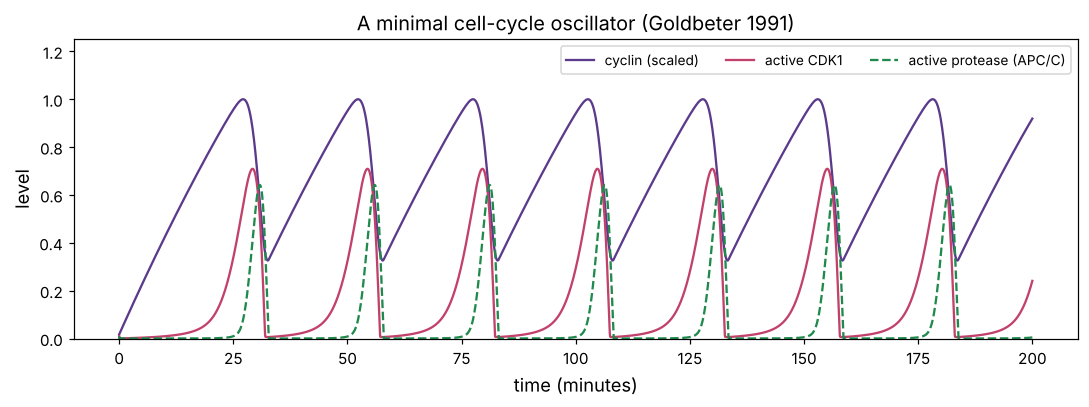

CDK1 peaks at [ 29.2  54.4  79.5 104.7 129.9 155.1 180.2] min; period about 25.2 min


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from scipy.integrate import solve_ivp

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

P = dict(vi=0.025, vd=0.25, Kd=0.02, kd=0.01, VM1=3.0, V2=1.5, VM3=1.0, V4=0.5, K=0.005, Kc=0.5)
def goldbeter(t, y, p=P):
    C, M, X = y
    V1 = p["VM1"] * C / (p["Kc"] + C)
    V3 = p["VM3"] * M
    dC = p["vi"] - p["vd"] * X * C / (p["Kd"] + C) - p["kd"] * C
    dM = V1 * (1 - M) / (p["K"] + 1 - M) - p["V2"] * M / (p["K"] + M)
    dX = V3 * (1 - X) / (p["K"] + 1 - X) - p["V4"] * X / (p["K"] + X)
    return [dC, dM, dX]

sol = solve_ivp(goldbeter, (0, 200), [0.01, 0.01, 0.01], max_step=0.1, rtol=1e-8)
t, (C, M, X) = sol.t, sol.y
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t, C / C.max(), color="#5b3a8c", label="cyclin (scaled)"); ax.plot(t, M, color="#c2416b", label="active CDK1")
ax.plot(t, X, color="#1f8a4c", ls="--", label="active protease (APC/C)")
ax.set_xlabel("time (minutes)"); ax.set_ylabel("level"); ax.legend(loc="upper right", ncol=3, fontsize=9); ax.set_ylim(0, 1.25)
ax.set_title("A minimal cell-cycle oscillator (Goldbeter 1991)")
save_fig("oscillator"); plt.show()

peaks = [t[i] for i in range(1, len(t) - 1) if M[i] > 0.5 and M[i] >= M[i - 1] and M[i] > M[i + 1]]
period = np.diff(peaks)[-3:].mean()
R["period"] = f"{period:.0f}"
print(f"CDK1 peaks at {np.round(peaks, 1)} min; period about {period:.1f} min")

![Figure P7-1. Cyclin slowly accumulates until it flips CDK1 on (mitosis). CDK1 switches on the protease, which destroys cyclin, CDK1 drops, and the cycle restarts. No external timer is needed: the oscillation comes from the feedback loop itself.](images/oscillator.png)

The model ticks with a period of about 25 minutes, similar to the fast, gap-free cycles of an early embryo. In adult cells the clock is slowed and gated by checkpoints and by growth signals. Chapter 17 explores what makes circuits like this oscillate, and chapter 18 adds randomness.

## Checkpoints: the brakes

| Checkpoint | Question | Key players |
|---|---|---|
| **Restriction point** (late G1) | Are there enough growth signals to commit to dividing? | cyclin D–CDK4/6, **Rb**, E2F |
| **G1/S DNA damage** | Is the DNA intact before copying it? | ATM, **p53**, p21 |
| **G2/M** | Was copying complete and correct? | ATR, CHK1 |
| **Spindle assembly** (M) | Is every chromosome attached? | MAD2, BUB1 |

The **restriction point** is where most cancers cheat. In G1, the protein **Rb** (retinoblastoma protein) holds the transcription factor **E2F**, which switches on the genes needed for S phase. Growth signals make cyclin D, which with CDK4/6 phosphorylates Rb; phosphorylated Rb lets go of E2F, and the cell is committed. Almost every cancer disables this brake somehow: deleting *RB1*, deleting the CDK inhibitor *CDKN2A* (p16), or amplifying cyclin D. The **CDK4/6 inhibitors** palbociclib, ribociclib and abemaciclib put the brake back on and are standard treatment for the most common type of breast cancer.

The **DNA-damage checkpoint** is run by **p53**, which you met in chapters P3 and P6. Normally p53 is destroyed within minutes of being made. DNA damage activates kinases (ATM, ATR) that phosphorylate p53, stopping its destruction. The p53 level rises and it switches on its target genes: *CDKN1A* (p21, which blocks CDKs and halts the cycle), DNA repair genes, and, if the damage is too severe, genes that trigger cell death. This is why p53 is called the guardian of the genome, and why it is mutated in about half of all cancers.

## Watching the cycle: DNA content

How do biologists measure where cells are in the cycle? A cell in G1 has two copies of the genome (written **2N**), a cell in G2 or M has four (**4N**), and S-phase cells are in between. Stain the DNA with a fluorescent dye and pass the cells one by one through a laser (**flow cytometry**, chapter P11): the brightness of each cell measures its DNA content. Let's simulate what that looks like for a growing culture and for two drugs.

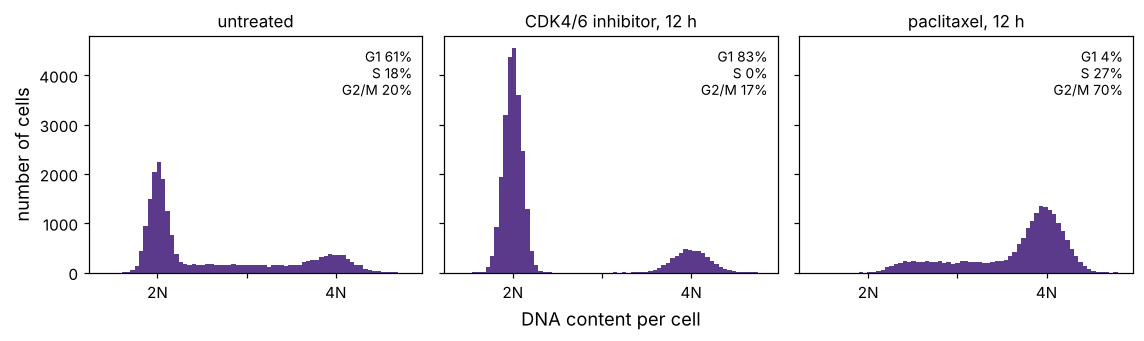

In [2]:
rng = np.random.default_rng(3)
DUR = {"G1": 11, "S": 8, "G2": 4, "M": 1}
T = sum(DUR.values())

def sample_ages(n):
    """Ages in a steadily growing population: young cells outnumber old ones (density ∝ 2^(-age/T))."""
    u = rng.random(n)
    return -T * np.log2(1 - u / 2)

def phase_content(a):
    return np.where(a < DUR["G1"], 2.0, np.where(a < DUR["G1"] + DUR["S"], 2 + 2 * (a - DUR["G1"]) / DUR["S"], 4.0))

def dna_content(age, treatment=None, hours=12):
    """DNA content after `hours` of treatment. Each cell's age advances; drugs stop it at their block point."""
    a = age + hours
    if treatment is None:
        a = age
    elif treatment == "paclitaxel":              # cells that reach mitosis cannot leave it
        a = np.minimum(a, T - 0.5)
    elif treatment == "CDK4/6 inhibitor":        # cells stop at the restriction point in G1 ...
        rp = 0.6 * DUR["G1"]
        before = age < rp
        divided = ~before & (a >= T)             # ... or, if already past it, finish the cycle, divide, and stop in the next G1
        a = np.where(before, np.minimum(a, rp), np.where(divided, np.minimum(a - T, rp), a))
        a = np.concatenate([a, a[divided]])      # each division makes two cells
    content = phase_content(a)
    return content * (1 + 0.05 * rng.standard_normal(content.size))   # measurement noise

ages = sample_ages(20000)
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
fractions = {}
for ax, tr in zip(axs, [None, "CDK4/6 inhibitor", "paclitaxel"]):
    d = dna_content(ages, tr)
    ax.hist(d, bins=np.linspace(1.4, 4.8, 70), color="#5b3a8c")
    g1, s, g2m = np.mean(d < 2.4), np.mean((d >= 2.4) & (d < 3.6)), np.mean(d >= 3.6)
    fractions[tr or "untreated"] = (g1, s, g2m)
    ax.set_title(f"{tr}, 12 h" if tr else "untreated", fontsize=11); ax.set_xticks([2, 3, 4], ["2N", "", "4N"])
    ax.text(0.97, 0.95, f"G1 {g1:.0%}\nS {s:.0%}\nG2/M {g2m:.0%}", transform=ax.transAxes, ha="right", va="top", fontsize=9)
axs[0].set_ylabel("number of cells"); axs[1].set_xlabel("DNA content per cell")
save_fig("flow"); plt.show()
R["g1_un"] = f"{fractions['untreated'][0]:.0%}"; R["g2m_tax"] = f"{fractions['paclitaxel'][2]:.0%}"; R["g1_cdk"] = f"{fractions['CDK4/6 inhibitor'][0]:.0%}"

![Figure P7-2. Simulated flow cytometry of DNA content. An untreated growing culture shows a big 2N (G1) peak, a smaller 4N (G2/M) peak and S-phase cells in between. After 12 hours, a CDK4/6 inhibitor has trapped most cells in G1; paclitaxel has trapped many in mitosis at 4N.](images/flow.png)

In an untreated culture about 61% of cells fall in the G1 gate (a little more than the 11/24 of the cycle that G1 takes, because a growing population has more young cells than old). After 12 hours with a CDK4/6 inhibitor, 83% are in G1; after 12 hours with paclitaxel, 70% have 4N DNA. Real cell-cycle experiments look exactly like this, and so does the first tab of the playground below, where you can grow a culture, add a drug or DNA damage, and watch both the DNA histogram and the cell count. Try paclitaxel and keep running: a rare resistant cell takes over, which is the central problem of cancer treatment (chapter 19).

::playground animations/cycle_lab.html 660

## How fast do tumours grow?

Cells that divide without limit grow exponentially. A tumour starting from one cell needs about 30 doublings to reach a billion cells (roughly 1 cm³, about 1 gram), which is around the smallest size usually detectable by imaging or touch, and about 40 to reach a trillion cells (about 1 kg), which is often lethal.

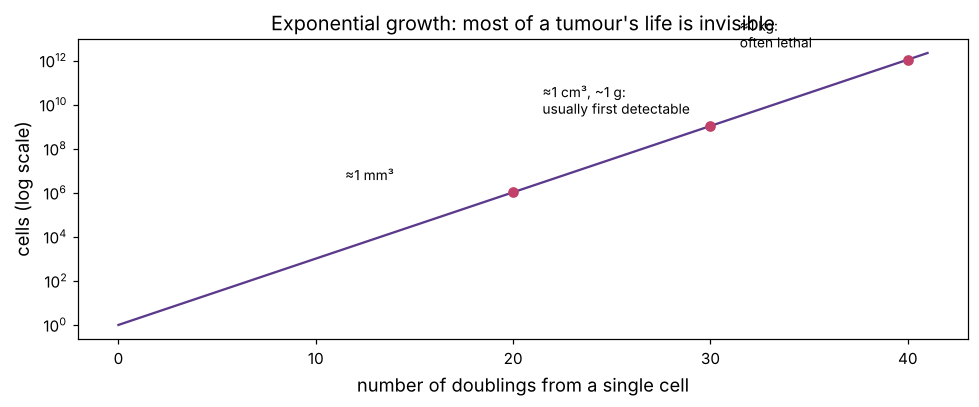

volume doubling time  30 days -> 30 doublings take   2.5 years
volume doubling time 100 days -> 30 doublings take   8.2 years
volume doubling time 300 days -> 30 doublings take  24.7 years


In [3]:
doublings = np.arange(0, 42)
cells = 2.0 ** doublings
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogy(doublings, cells, color="#5b3a8c")
for d, label in [(30, "≈1 cm³, ~1 g:\nusually first detectable"), (40, "≈1 kg:\noften lethal"), (20, "≈1 mm³")]:
    ax.scatter(d, 2.0 ** d, color="#c2416b", zorder=3); ax.annotate(label, (d, 2.0 ** d), xytext=(-110, 8), textcoords="offset points", fontsize=9)
ax.set_xlabel("number of doublings from a single cell"); ax.set_ylabel("cells (log scale)")
ax.set_title("Exponential growth: most of a tumour's life is invisible")
save_fig("tumour_growth"); plt.show()

# if the observed volume doubling time is 100 days, how old is a 1 cm tumour?
for td in [30, 100, 300]:
    print(f"volume doubling time {td:3d} days -> 30 doublings take {30 * td / 365:5.1f} years")
R["years_100"] = f"{30 * 100 / 365:.0f}"

![Figure P7-3. Doublings needed to grow from one cell. Thirty doublings give about a billion cells, around the size at which most tumours are first found; only ten more give a trillion.](images/tumour_growth.png)

Real tumours grow much more slowly than their cells divide, because many cells die or stop dividing: the *volume* doubling time of human tumours ranges from weeks to more than a year. With a doubling time of 100 days, a 1 cm tumour has been growing for about 8 years. Most of a tumour's history happens before anyone can see it, which is why early detection (screening, blood tests for tumour DNA) matters, and why tumours are already genetically diverse when found (chapter 19).

## Ageing cells: telomeres and senescence

Chromosomes are linear, and DNA polymerase cannot fully copy the very end of a linear molecule (it needs a primer ahead of it). So each division shortens the chromosome ends a little. Protecting the ends are **telomeres**: thousands of repeats of `TTAGGG`, about 10,000 bases in young human cells, capped by proteins. When telomeres get too short, the cell sees its chromosome ends as DNA breaks, p53 is activated, and the cell permanently stops dividing: **senescence**. Leonard Hayflick found in 1961 that normal human cells in culture divide only about 40–60 times; this is the **Hayflick limit**.

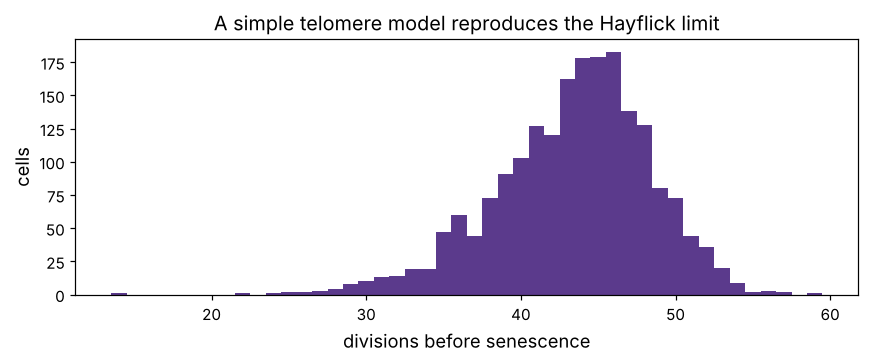

mean 43.4 divisions (90% of cells between 35 and 51)


In [4]:
def lifespan(n_cells=2000, start=10_000, loss=(50, 100), critical=5_000):
    """Divisions until the shortest of 46 chromosome ends falls below the critical length."""
    out = []
    for _ in range(n_cells):
        tel = start + rng.normal(0, 800, 46)
        k = 0
        while tel.min() > critical:
            tel -= rng.uniform(*loss, 46); k += 1
        out.append(k)
    return np.array(out)

div = lifespan()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(div, bins=np.arange(div.min(), div.max() + 2) - 0.5, color="#5b3a8c")
ax.set_xlabel("divisions before senescence"); ax.set_ylabel("cells"); ax.set_title("A simple telomere model reproduces the Hayflick limit")
save_fig("hayflick"); plt.show()
R["hay_mean"] = f"{div.mean():.0f}"; R["hay_lo"] = int(np.percentile(div, 5)); R["hay_hi"] = int(np.percentile(div, 95))
print(f"mean {div.mean():.1f} divisions (90% of cells between {np.percentile(div, 5):.0f} and {np.percentile(div, 95):.0f})")

![Figure P7-4. Divisions before the shortest telomere drops below a critical length, in a model where each of 46 chromosome ends starts near 10,000 bases and loses 50–100 bases per division.](images/hayflick.png)

The model gives about 43 divisions on average (35–51 for most cells), close to Hayflick's measurement. Telomere shortening is a built-in brake on runaway division, a tumour-suppressing mechanism. To grow forever, about 85–90% of cancers switch on **telomerase**, the enzyme that rebuilds telomeres (normally active only in stem cells and germ cells); most of the rest use a recombination-based workaround. Often the switch is a single mutation in the *TERT* promoter that creates a new transcription-factor binding site, one of the most common non-coding mutations in cancer.

## Programmed cell death: apoptosis

About 50–70 billion cells in an adult die every day, almost all by **apoptosis**, a tidy, programmed suicide: the cell shrinks, chops up its DNA and breaks into small packages that immune cells eat, without causing inflammation. It removes damaged, infected, unneeded or dangerous cells, and it sculpts the body during development (the webbing between your fingers disappeared by apoptosis).

Two routes lead to it:

- **Intrinsic (mitochondrial)**: internal stress (DNA damage via p53, lack of growth signals) activates the proteins **BAX** and **BAK**, which punch holes in mitochondria. Cytochrome c leaks out and switches on **caspases**, protein-cutting enzymes that dismantle the cell. Survival proteins of the **BCL-2** family hold BAX and BAK back.
- **Extrinsic (death receptors)**: immune cells deliver a death signal (FAS ligand, TRAIL) to receptors on the target cell, activating caspases directly. This is one way T cells kill infected and cancer cells (chapter P10).

The second tab of the playground models the intrinsic decision as a balance. Many blood cancers survive by overproducing BCL-2. The drug **venetoclax** (approved 2016) blocks BCL-2 and tips the balance back towards death.

:::idea
Cancer needs both an accelerator and broken brakes. It must keep dividing (stuck accelerator: growth signals, cyclin D, MYC), ignore stop signals (broken brakes: Rb, p53, p16), avoid death (BCL-2 up, p53 down), and divide without limit (telomerase). Chapter P12 organises these into the **hallmarks of cancer**, and the cell cycle machinery in this chapter is where many of them act.
:::

## Summary

| Idea | One line |
|---|---|
| Phases | G1 → S (copy DNA) → G2 → M (divide); G0 = resting |
| Clock | cyclins activate CDKs; cyclin destruction resets the clock |
| Restriction point | cyclin D–CDK4/6 phosphorylates Rb, releasing E2F; target of palbociclib |
| p53 | senses DNA damage; halts the cycle via p21 or triggers apoptosis |
| Telomeres | shorten each division; senescence after ~50 divisions; cancers reactivate telomerase |
| Apoptosis | caspases dismantle the cell; BCL-2 blocks it; venetoclax unblocks it |

:::check
1. A cell has 4N DNA content. Which phases could it be in? *(G2 or M.)*
2. What does Rb do, and how does CDK4/6 inactivate it? *(It holds E2F; phosphorylation by cyclin D–CDK4/6 releases E2F.)*
3. Why does destroying cyclin B allow a cell to leave mitosis? *(CDK1 needs cyclin to be active; without it, CDK1 switches off.)*
4. A tumour of 10⁹ cells has a volume doubling time of 60 days. How long until it reaches 10¹² cells if nothing changes? *(10 doublings, about 600 days.)*
5. Why would a drug that blocks BCL-2 kill some cancer cells but spare most normal cells? *(Those cancers depend on extra BCL-2 to survive their internal stress; normal cells are not near the death threshold.)*
:::

:::exercise
In the Goldbeter model, the rate of cyclin synthesis $v_i$ sets how fast cyclin builds up. Run the model for $v_i$ from 0.01 to 0.1 and plot the period of the oscillation against $v_i$. Does faster cyclin synthesis speed up the clock?
:::

<details><summary>Solution</summary>

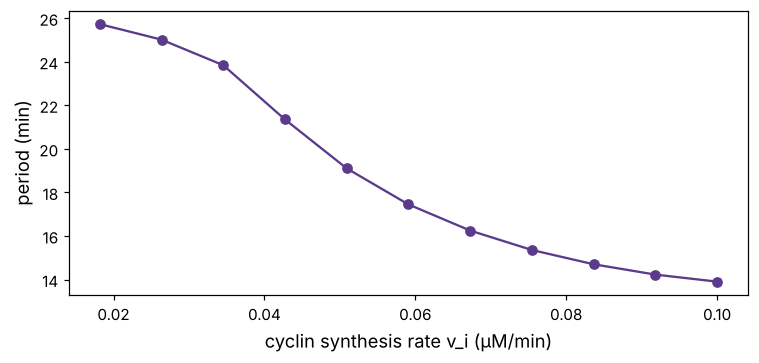

['0.010: nan', '0.018: 25.7', '0.026: 25.0', '0.035: 23.8', '0.043: 21.4', '0.051: 19.1', '0.059: 17.4', '0.067: 16.2', '0.075: 15.4', '0.084: 14.7', '0.092: 14.2', '0.100: 13.9']


In [5]:
def period_for(vi):
    p = dict(P, vi=vi)
    sol = solve_ivp(goldbeter, (0, 400), [0.01, 0.01, 0.01], args=(p,), max_step=0.1, rtol=1e-8)
    t, M = sol.t, sol.y[1]
    pk = [t[i] for i in range(1, len(t) - 1) if M[i] > 0.5 and M[i] >= M[i - 1] and M[i] > M[i + 1]]
    return np.diff(pk)[-3:].mean() if len(pk) > 4 else np.nan

vis = np.linspace(0.01, 0.1, 12)
periods = [period_for(v) for v in vis]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(vis, periods, "o-", color="#5b3a8c"); ax.set_xlabel("cyclin synthesis rate v_i (µM/min)"); ax.set_ylabel("period (min)")
save_fig("period_vs_vi"); plt.show()
print([f"{v:.3f}: {p:.1f}" for v, p in zip(vis, periods)])

Faster cyclin synthesis shortens the period: cyclin reaches the threshold for switching on CDK1 sooner. This is one reason growth signals that raise cyclin levels speed up division. (At very low synthesis rates cyclin may never reach the threshold, and the clock stops: the cell rests.)

</details>